# Dar_010 — P1 SPICE coverage and explicit reference-sphere geometry
**D19:** downloaded LSK, text PCK, DE421 SPK, lunar binary PCK and lunar frame kernel.
Calculate a **modeled reference-sphere benchmark**, not measured illumination or a mission
power/communications simulation: hourly Sun/Earth center elevation over 2020-11-01 to
2020-12-01 at the seven original region rectangle centers.

This is a clearly stated illustrative interval, not a supplied mission profile. No terrain
horizon, equipment load, solar-disc integration, relay architecture or outage model is supplied.

In [1]:
from pathlib import Path
import sys, json, io, re, zipfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT / "env_algo_task/EDA/shared"), str(ROOT / "env_algo_task/EDA/Moon/Stage3_Requirements"),str(ROOT)]
DATA = ROOT/'env_algo_task/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from notebooks.shared.inspection import verify_run, check_input
from research_p1_readers import (pilot_files, pin_source, read_pds4, pds4_chunks,
    pds4_definition, pds4_image, dose_profiles, pds3_number)
import research_p1_readers
def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def save_findings(run, findings):
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(Markdown('**Executed findings**')); display(findings)
def pin(run, path): return pin_source(run, path)
def short(region): return region.split('_',2)[-1].replace('_',' ')

## Frames, coverage and cross-checks
Use the downloaded DE421-compatible `MOON_ME` frame and an explicit 1737.4 km reference
sphere. Convert region-center coordinates using the existing lunar CRS definitions.
Load only the pinned kernels; inspect SPK/PCK coverage and fail if scenario epochs are
unsupported. Use geometric positions (`NONE` aberration correction); compare one manual
surface-relative elevation against NAIF `azlcpo` with the same assumptions.
Source: [NAIF azlcpo](https://naif.jpl.nasa.gov/pub/naif/toolkit_docs/C/cspice/azlcpo_c.html).

Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b


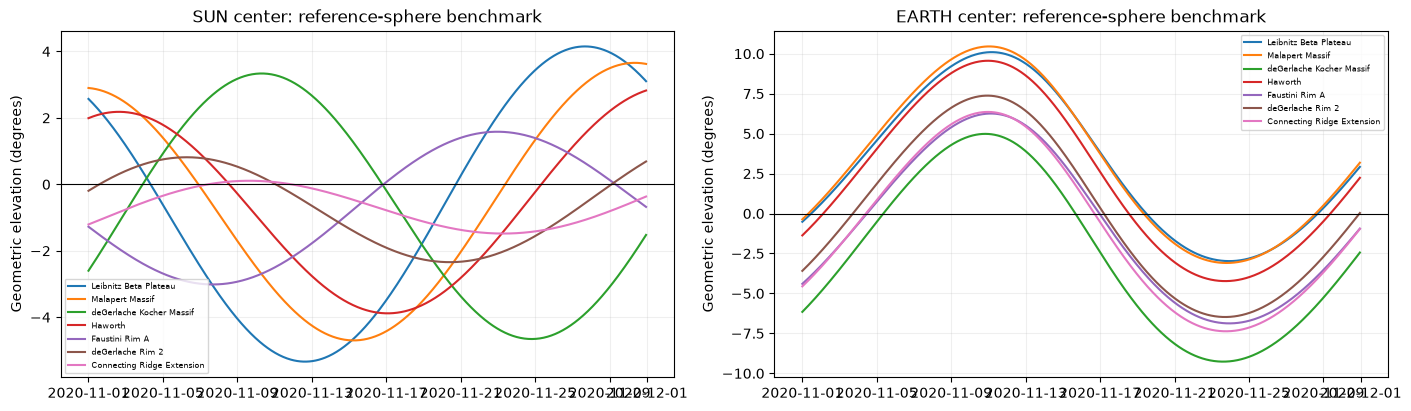

**Executed findings**

{'epochs_per_region_target': 720,
 'modeled_geometry_rows': 10080,
 'kernel_files': 5,
 'cross_checks': 14,
 'maximum_cross_check_error_deg': np.float64(1.3322676295501878e-15),
 'holds': ['Reference-sphere benchmark only; terrain horizons not supplied',
  'No measured illumination/PSR classification',
  'No darkness/outage duration or power/link assessment',
  'Illustrative interval is not an intended mission']}

,region,target,count,min,median,max
0,A3CLR22_10_Leibnitz_Beta_Plateau,EARTH,720,-2.975561,2.326836,10.098342
1,A3CLR22_10_Leibnitz_Beta_Plateau,SUN,720,-5.337250,-0.670564,4.151101
2,A3CLR22_11_Malapert_Massif,EARTH,720,-3.093263,2.467859,10.456101
3,A3CLR22_11_Malapert_Massif,SUN,720,-4.698723,-0.619317,3.657045
4,A3CLR22_12_deGerlache_Kocher_Massif,EARTH,720,-9.266142,-3.321674,4.984699
5,A3CLR22_12_deGerlache_Kocher_Massif,SUN,720,-4.656777,-0.934500,3.336738
6,A3CLR22_2_Haworth,EARTH,720,-4.227229,1.459972,9.559445
7,A3CLR22_2_Haworth,SUN,720,-3.883621,-0.594308,2.824070
8,A3CLR22_3_Faustini_Rim_A,EARTH,720,-6.872944,-1.538975,6.257051
9,A3CLR22_3_Faustini_Rim_A,SUN,720,-3.013868,-0.555379,1.583136


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\env_algo_task\data\processed\analysis\dar_010_research_geometry\20261109T142644587403Z_2ca66b


In [2]:
import spiceypy as spice
from pyproj import Transformer
from notebooks.shared.processing import MOON_CRS,MOON_GEOGRAPHIC
from moon_p1_analysis import region_footprints
START_UTC='2020-11-01T00:00:00';STOP_UTC='2020-12-01T00:00:00';STEP_HOURS=1
regions=region_footprints(DATA)
with Run(ROOT,'analysis/dar_010_research_geometry',{'datasets':['D19'],'start':START_UTC,'stop_exclusive':STOP_UTC,'step_hours':STEP_HOURS,
    'model':'terrain-free reference-sphere target-center elevation','reference_radius_km':1737.4,'frame':'MOON_ME','aberration':'NONE'},'Moon/Environmental_Context/Dar_010_research_spice_geometry.ipynb') as run:
    run.input(Path(research_p1_readers.__file__))
    files=[]
    for suffix in ['.tls','.tpc','.bsp','.bpc','.tf']:files.extend(pilot_files(DATA,'D19',suffix))
    for p in files:pin(run,p)
    spice.kclear()
    try:
        for p in files:spice.furnsh(str(p))
        start,stop=spice.str2et(START_UTC),spice.str2et(STOP_UTC)
        # Calendar-hour UTC grid first: uniform ET seconds can admit a rounded stop-boundary sample.
        utc_epochs=pd.date_range(START_UTC,STOP_UTC,freq=f'{STEP_HOURS}h',inclusive='left',tz='UTC')
        times=np.array([spice.str2et(t.strftime('%Y-%m-%dT%H:%M:%S')) for t in utc_epochs])
        coverage=[]
        for p in files:
            if p.suffix=='.bsp':
                for body in spice.spkobj(str(p)):
                    window=spice.spkcov(str(p),int(body))
                    for i in range(spice.wncard(window)):
                        a,b=spice.wnfetd(window,i);coverage.append({'file':p.name,'kind':'SPK','object_id':int(body),'start_ET':a,'stop_ET':b})
            elif p.suffix=='.bpc':
                ids=spice.utils.support_types.SPICEINT_CELL(100)
                spice.pckfrm(str(p),ids)
                for frame in ids:
                    window=spice.pckcov(str(p),int(frame))
                    for i in range(spice.wncard(window)):
                        a,b=spice.wnfetd(window,i);coverage.append({'file':p.name,'kind':'PCK','object_id':int(frame),'start_ET':a,'stop_ET':b})
        pd.DataFrame(coverage).to_csv(run.path('kernel_time_coverage.csv'),index=False)
        project=Transformer.from_crs(MOON_CRS,MOON_GEOGRAPHIC,always_xy=True)
        geometry=[];crosscheck=[]
        for name,info in regions.items():
            # Input footprints are traceable in the existing completed thermal preparation.
            thermal=latest_completed_run(ROOT,'analysis/dar_001_temperature_local_time')
            expected=verify_run(thermal);check_input(thermal/'region_footprints.json',expected,{})
            run.input(thermal/'provenance.json');run.input(thermal/'region_footprints.json')
            west,south,east,north=info['bounds'];lon,lat=project.transform((west+east)/2,(south+north)/2)
            lonr,latr=np.deg2rad([lon,lat]);observer=spice.latrec(1737.4,lonr,latr);up=observer/np.linalg.norm(observer)
            for target in ['SUN','EARTH']:
                for j,et in enumerate(times):
                    target_pos,_=spice.spkpos(target,float(et),'MOON_ME','NONE','MOON')
                    vector=np.asarray(target_pos)-observer
                    elevation=float(np.rad2deg(np.arcsin(np.clip(np.dot(vector/np.linalg.norm(vector),up),-1,1))))
                    geometry.append({'region':name,'target':target,'utc':spice.et2utc(float(et),'ISOC',3),
                        'longitude_deg':lon,'latitude_deg':lat,'reference_sphere_center_elevation_deg':elevation,
                        'center_above_reference_horizon':elevation>0,'observer_target_range_km':np.linalg.norm(vector)})
                    if j==0:
                        state,_=spice.azlcpo('ELLIPSOID',target,float(et),'NONE',False,True,observer,'MOON','MOON_ME')
                        difference=elevation-np.rad2deg(state[2])
                        if abs(difference)>1e-7:raise ValueError('SPICE topocentric cross-check failed')
                        crosscheck.append({'region':name,'target':target,'elevation_difference_deg':difference})
        geometry=pd.DataFrame(geometry);geometry.to_csv(run.path('reference_sphere_sun_earth_geometry.csv'),index=False)
        pd.DataFrame(crosscheck).to_csv(run.path('topocentric_cross_checks.csv'),index=False)
        summary=geometry.groupby(['region','target']).reference_sphere_center_elevation_deg.agg(['count','min','median','max']).reset_index()
        summary.to_csv(run.path('reference_sphere_elevation_summary.csv'),index=False)
        fig,axes=plt.subplots(1,2,figsize=(14,4),layout='constrained')
        for ax,target in zip(axes,['SUN','EARTH']):
            for region,part in geometry.loc[geometry.target.eq(target)].groupby('region'):
                ax.plot(pd.to_datetime(part.utc),part.reference_sphere_center_elevation_deg,label=short(region))
            ax.axhline(0,color='black',lw=.8);ax.set(title=f'{target} center: reference-sphere benchmark',ylabel='Geometric elevation (degrees)')
            ax.legend(fontsize=6);ax.grid(alpha=.2)
        savefig(run,fig,'reference_sphere_geometry')
        save_findings(run,{'epochs_per_region_target':len(times),'modeled_geometry_rows':len(geometry),'kernel_files':len(files),
            'cross_checks':len(crosscheck),'maximum_cross_check_error_deg':max(abs(x['elevation_difference_deg']) for x in crosscheck),
            'holds':['Reference-sphere benchmark only; terrain horizons not supplied','No measured illumination/PSR classification',
                     'No darkness/outage duration or power/link assessment','Illustrative interval is not an intended mission']})
        display(summary)
    finally:
        spice.kclear()
OUT=run.directory;print('Completed:',OUT)

## Stage 3 role
Kernel coverage, frame consistency and a tested geometry calculation are prerequisites
for later dated environmental modeling. The zero-elevation line is only a reference-sphere
geometric horizon, not a local ridge horizon. These curves are not evidence that a base
receives power, has an Earth radio link, or survives darkness. D02/D03 mean-map context
remains distinct; M07/M08 actual power/link scenario records are still missing.